# Оценка A/B-экспериментов интернет-магазина

    Онлайн магазин с быстрой доставкой.
    Было проведено 3 эксперимента, каждый длился неделю.
    Метрика - средняя выручка с клиента за неделю эксперимента.
    Проверяем гипотезу о равенстве средних на уровне значимости 0.05.

Что делаю в ноутбуке:
1. оцениваю все три эксперимента t-test'ом и проверяю, что разбиение на группы корректное;
2. считаю MDE - какой эффект вообще можно было заметить;
3. на синтетических АА и АБ проверяю t-test и CUPED с разными ковариатами;
4. пересчитываю эксперименты с CUPED;
5. смотрю, что будет, если подглядывать в результаты каждый день.

## 0. Данные

Данные о продажах в файле `df_sales.csv`, одна строка - одна покупка:
- `user_id` - идентификатор пользователя
- `cost` - стоимость покупки
- `day` - день покупки
- `time` - время доставки (в минутах)

В `exp_dict.json` для каждого эксперимента записаны дни проведения и пользователи групп A и B.

In [1]:
import json
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05
np.random.seed(42)

In [2]:
df_sales = pd.read_csv('data/df_sales.csv')
df_sales['week'] = (df_sales['day'] - 1) // 7

with open('data/exp_dict.json', 'r') as f:
    exp_dict = json.load(f)

print(df_sales.shape, df_sales['user_id'].nunique(), df_sales['day'].max())
df_sales.describe()

(249894, 5) 50000 35


,user_id,cost,day,time,week
count,249894.000000,249894.000000,249894.000000,249894.000000,249894.000000
mean,36657.397176,2751.479795,18.177039,70.721115,2.001765
std,14435.228208,525.999436,10.093991,15.131931,1.414483
min,11649.000000,887.000000,1.000000,9.600000,0.000000
25%,24153.000000,2361.000000,9.000000,62.500000,1.000000
50%,36667.000000,2750.000000,18.000000,70.300000,2.000000
75%,49158.000000,3143.000000,27.000000,78.000000,3.000000
max,61648.000000,4623.000000,35.000000,342.900000,4.000000


In [3]:
for name, exp in exp_dict.items():
    print(name, 'дни', exp['days'], 'A:', len(exp['users_a']), 'B:', len(exp['users_b']))

exp1 дни [8, 9, 10, 11, 12, 13, 14] A: 1000 B: 1000
exp2 дни [15, 16, 17, 18, 19, 20, 21] A: 12000 B: 12000
exp3 дни [22, 23, 24, 25, 26, 27, 28] A: 25000 B: 25000


Посмотрим на число покупок по дням

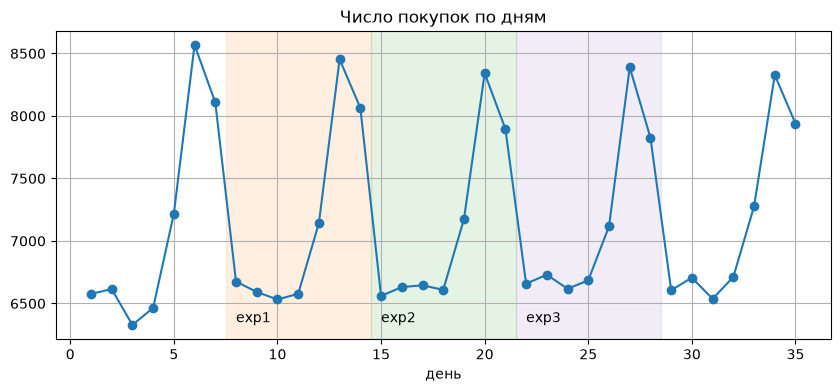

In [4]:
df_sales.groupby('day')['user_id'].count().plot(marker='o', figsize=(10, 4))
for (name, exp), color in zip(exp_dict.items(), ['C1', 'C2', 'C4']):
    plt.axvspan(exp['days'][0] - 0.5, exp['days'][-1] + 0.5, alpha=0.12, color=color)
    plt.text(exp['days'][0], 6350, name)
plt.title('Число покупок по дням')
plt.xlabel('день')
plt.grid()
plt.savefig('figures/sales_by_day.png', dpi=120, bbox_inches='tight')
plt.show()

Есть недельная сезонность: на 6-7 день недели покупок больше.</br>
Каждый эксперимент длится ровно неделю, поэтому сезонность на сравнение групп не влияет.

# 1. Оценка экспериментов t-test'ом

## 1.1. Метрики

Для каждого пользователя считаем сумму покупок за дни эксперимента.</br>
Если покупок не было - метрика 0, такие пользователи тоже должны остаться в выборке.

In [5]:
def get_metric(df_sales, users, days):
    """Выручка каждого пользователя за указанные дни.

    :param df_sales (pd.DataFrame): таблица покупок
    :param users (list): пользователи группы
    :param days (list): дни, за которые считаем метрику

    :return (pd.Series): выручка пользователей, индекс - user_id
    """
    revenue = df_sales[df_sales['day'].isin(days)].groupby('user_id')['cost'].sum()
    return revenue.reindex(users, fill_value=0)


metrics = {}
for name, exp in exp_dict.items():
    a = get_metric(df_sales, exp['users_a'], exp['days'])
    b = get_metric(df_sales, exp['users_b'], exp['days'])
    metrics[name] = (a, b)
    print(name, 'доля пользователей без покупок:', round(np.mean(np.concatenate([a, b]) == 0), 3))

exp1 доля пользователей без покупок: 0.09
exp2 доля пользователей без покупок: 0.086
exp3 доля пользователей без покупок: 0.086


## 1.2. Проверка разбиения

Перед тем как смотреть на результат, проверим, что группы были одинаковые до эксперимента.</br>
Берём выручку за неделю до эксперимента и сравниваем группы - значимой разницы быть не должно.</br>
У exp1 предыдущая неделя - это первая неделя данных.

In [6]:
for name, exp in exp_dict.items():
    prev_days = [d - 7 for d in exp['days']]
    a = get_metric(df_sales, exp['users_a'], prev_days)
    b = get_metric(df_sales, exp['users_b'], prev_days)
    print(f'{name}: до эксперимента pvalue = {stats.ttest_ind(a, b).pvalue:.3f}')

exp1: до эксперимента pvalue = 0.564
exp2: до эксперимента pvalue = 0.778
exp3: до эксперимента pvalue = 0.751


До экспериментов группы не отличаются, разбиение выглядит нормально.

## 1.3. t-test

Кроме p-value посчитаем доверительный интервал для разницы средних - он показывает, какой эффект совместим с данными.

In [7]:
def ttest_with_ci(a, b, alpha=ALPHA):
    """t-test и доверительный интервал для разницы средних b - a."""
    delta = b.mean() - a.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    z = stats.norm.ppf(1 - alpha / 2)
    pvalue = stats.ttest_ind(a, b).pvalue
    return delta, (delta - z * se, delta + z * se), pvalue


rows = []
for name, (a, b) in metrics.items():
    delta, ci, pvalue = ttest_with_ci(a, b)
    rows.append({
        'эксперимент': name,
        'n в группе': len(a),
        'среднее A': round(a.mean(), 1),
        'среднее B': round(b.mean(), 1),
        'разница': round(delta, 1),
        'ДИ': f'[{ci[0]:.1f}; {ci[1]:.1f}]',
        'разница, %': round(delta / a.mean() * 100, 2),
        'pvalue': round(pvalue, 4),
    })
df_ttest = pd.DataFrame(rows).set_index('эксперимент')
df_ttest

,n в группе,среднее A,среднее B,разница,ДИ,"разница, %",pvalue
эксперимент,,,,,,,
exp1,1000,2709.8,2798.4,88.6,[-20.6; 197.8],3.27,0.1119
exp2,12000,2740.4,2821.0,80.6,[48.1; 113.0],2.94,0.0000
exp3,25000,2749.7,2749.3,-0.4,[-22.6; 21.8],-0.01,0.9736


# 2. MDE

Какой эффект могли обнаружить при таком размере групп? Мощность 80%.

$$
MDE = \left( \Phi^{-1}(1 - \alpha/2) + \Phi^{-1}(1 - \beta) \right) \sqrt{\frac{\sigma_A^2 + \sigma_B^2}{n}}
$$

In [8]:
def estimate_mde(n, std, alpha=ALPHA, beta=0.2):
    """MDE для теста двух средних при n пользователях в каждой группе."""
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(1 - beta)
    return z * np.sqrt(2 * std ** 2 / n)


df_ttest['MDE'] = [round(estimate_mde(len(a), np.std(np.concatenate([a, b]))), 1) for a, b in metrics.values()]
df_ttest['MDE, %'] = (df_ttest['MDE'] / df_ttest['среднее A'] * 100).round(1)
df_ttest[['n в группе', 'разница, %', 'pvalue', 'MDE, %']]

,n в группе,"разница, %",pvalue,"MDE, %"
эксперимент,,,,
exp1,1000,3.27,0.1119,5.8
exp2,12000,2.94,0.0000,1.7
exp3,25000,-0.01,0.9736,1.2


exp1 на 1000 пользователей в группе мог найти только эффект порядка 5-6%, а такие эффекты бывают редко.</br>
Незначимый результат в exp1 не значит, что эффекта нет - тест просто был слишком маленький.

# 3. CUPED

Хотим снизить дисперсию метрики за счёт данных до эксперимента:

$$
Y_{cuped} = Y - \theta X, \quad \theta = \frac{cov(X, Y)}{var(X)}
$$

Чем сильнее ковариата $X$ коррелирует с метрикой, тем сильнее падает дисперсия (в $1 - \rho^2$ раз).

## 3.1. Выбор ковариаты

Стандартный вариант - выручка пользователя за предыдущую неделю.</br>
Сравню его со средним чеком пользователя за всю историю до эксперимента.</br>
Смотрю на 4-ю неделю (дни 22-28), до неё есть 3 недели истории.

In [9]:
def get_covariates(df_sales, users, first_day):
    """Ковариаты по данным до first_day.

    prev_week - выручка за 7 дней до эксперимента
    avg_check - средний чек пользователя за всю историю до эксперимента
    (у кого покупок не было - средний чек по всем)
    """
    history = df_sales[df_sales['day'] < first_day]
    prev_week = history[history['day'] >= first_day - 7].groupby('user_id')['cost'].sum()
    avg_check = history.groupby('user_id')['cost'].mean()
    return pd.DataFrame({
        'prev_week': prev_week.reindex(users, fill_value=0),
        'avg_check': avg_check.reindex(users).fillna(history['cost'].mean()),
    })


users = df_sales['user_id'].unique()
days = list(range(22, 29))
df_metric = get_covariates(df_sales, users, days[0])
df_metric['metric'] = get_metric(df_sales, users, days)
df_metric.corrwith(df_metric['metric'])

prev_week   -0.167787
avg_check    0.312466
metric       1.000000
dtype: float64

Выручка за прошлую неделю коррелирует с метрикой **отрицательно**.</br>
Посмотрим, сколько покупок обычно делает пользователь за неделю:

In [10]:
df_sales.groupby(['user_id', 'week']).size().unstack(fill_value=0)[3].value_counts().sort_index()

3
0     4289
1    41401
2     4310
Name: count, dtype: int64

Почти все покупают ровно раз в неделю. Видимо, если у пользователя на прошлой неделе было 2 покупки, на этой неделе скорее будет 0, и наоборот - отсюда отрицательная связь.</br>
А вот средний чек - устойчивая характеристика пользователя, он коррелирует с метрикой заметно сильнее.

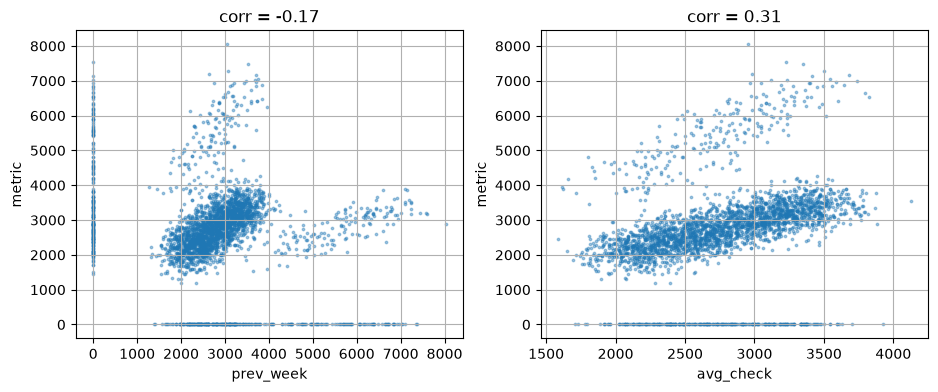

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['prev_week', 'avg_check']):
    sample = df_metric.sample(3000, random_state=1)
    ax.scatter(sample[col], sample['metric'], s=3, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel('metric')
    ax.set_title(f'corr = {df_metric[col].corr(df_metric["metric"]):.2f}')
    ax.grid()
plt.savefig('figures/covariates.png', dpi=120, bbox_inches='tight')
plt.show()

## 3.2. Проверим корректность и сравним мощности

Синтетические АА и АБ эксперименты на данных 4-й недели.</br>
В АБ добавляем к группе B эффект +2% от средней выручки.

In [12]:
def calculate_theta(y_control, y_pilot, x_control, x_pilot):
    """Theta по данным обеих групп."""
    y = np.hstack([y_control, y_pilot])
    x = np.hstack([x_control, x_pilot])
    return np.cov(x, y)[0, 1] / x.var(ddof=1)


def check_cuped(y_a, y_b, x_a, x_b):
    """pvalue t-test'а после CUPED."""
    theta = calculate_theta(y_a, y_b, x_a, x_b)
    return stats.ttest_ind(y_a - theta * x_a, y_b - theta * x_b).pvalue


def plot_pvalue_distribution(dict_pvalues, title, path=None):
    """Рисует эмпирические функции распределения pvalue."""
    X = np.linspace(0, 1, 1000)
    for key, pvalues in dict_pvalues.items():
        Y = [np.mean(np.array(pvalues) < x) for x in X]
        plt.plot(X, Y, label=key)
    plt.plot([0, 1], [0, 1], '--k', alpha=0.8)
    plt.title(title)
    plt.xlabel('p-value')
    plt.legend()
    plt.grid()
    if path:
        plt.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()

In [13]:
y = df_metric['metric'].values
x_prev = df_metric['prev_week'].values
x_check = df_metric['avg_check'].values

sample_size = 5000
effect = 0.02 * y.mean()

dict_pvalues = defaultdict(list)
for _ in range(2000):
    idx_a, idx_b = np.random.choice(len(y), (2, sample_size), False)
    y_a, y_b = y[idx_a], y[idx_b]
    for kind, y_b_ in [('AA', y_b), ('AB', y_b + effect)]:
        dict_pvalues[f'ttest {kind}'].append(stats.ttest_ind(y_a, y_b_).pvalue)
        dict_pvalues[f'cuped prev_week {kind}'].append(check_cuped(y_a, y_b_, x_prev[idx_a], x_prev[idx_b]))
        dict_pvalues[f'cuped avg_check {kind}'].append(check_cuped(y_a, y_b_, x_check[idx_a], x_check[idx_b]))

{k: round(np.mean(np.array(v) < ALPHA), 3) for k, v in dict_pvalues.items()}

{'ttest AA': np.float64(0.04),
 'cuped prev_week AA': np.float64(0.042),
 'cuped avg_check AA': np.float64(0.041),
 'ttest AB': np.float64(0.589),
 'cuped prev_week AB': np.float64(0.606),
 'cuped avg_check AB': np.float64(0.636)}

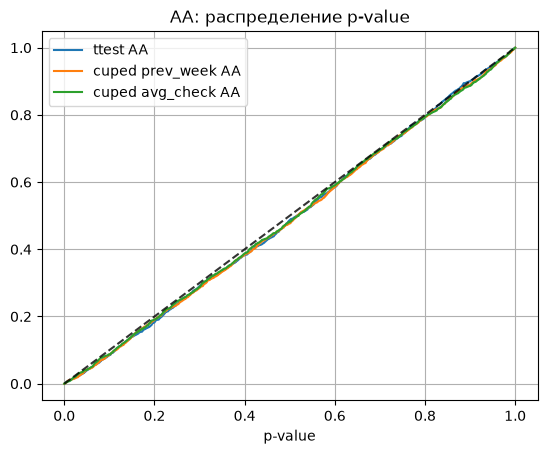

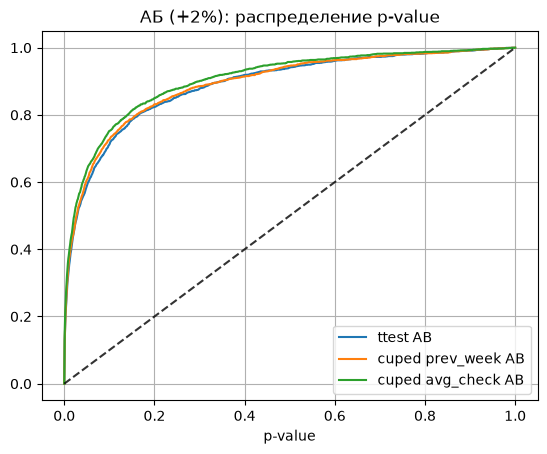

In [14]:
plot_pvalue_distribution({k: v for k, v in dict_pvalues.items() if k.endswith('AA')}, 'АА: распределение p-value')
plot_pvalue_distribution({k: v for k, v in dict_pvalues.items() if k.endswith('AB')}, 'АБ (+2%): распределение p-value',
                         path='figures/cuped_ab.png')

В АА все три варианта дают около 5% ложных срабатываний - CUPED ошибку I рода не ломает.</br>
В АБ CUPED по прошлой неделе почти не помогает, по среднему чеку мощность выше, но ненамного: корреляция 0.31 даёт только ~10% снижения дисперсии.

# 4. Пересчитаем эксперименты с CUPED

In [15]:
rows = []
for name, exp in exp_dict.items():
    a, b = metrics[name]
    cov_a = get_covariates(df_sales, exp['users_a'], exp['days'][0])['avg_check']
    cov_b = get_covariates(df_sales, exp['users_b'], exp['days'][0])['avg_check']
    theta = calculate_theta(a, b, cov_a, cov_b)
    a_cuped, b_cuped = a - theta * cov_a, b - theta * cov_b
    _, ci, p_cuped = ttest_with_ci(a_cuped, b_cuped)
    rows.append({
        'эксперимент': name,
        'pvalue ttest': df_ttest.loc[name, 'pvalue'],
        'pvalue cuped': round(p_cuped, 4),
        'ДИ cuped': f'[{ci[0]:.1f}; {ci[1]:.1f}]',
        'снижение дисперсии': f'{1 - np.var(np.concatenate([a_cuped, b_cuped])) / np.var(np.concatenate([a, b])):.0%}',
    })
pd.DataFrame(rows).set_index('эксперимент')

,pvalue ttest,pvalue cuped,ДИ cuped,снижение дисперсии
эксперимент,,,,
exp1,0.1119,0.0663,[-6.6; 203.9],7%
exp2,0.0000,0.0000,[55.7; 117.6],9%
exp3,0.9736,0.8207,[-18.7; 23.5],10%


У exp1 история - всего одна неделя, поэтому средний чек там оценивается по 1-2 покупкам и снижение дисперсии меньше.

# 5. Подглядывание

Что будет, если смотреть на p-value каждый день и останавливать тест, как только он прокрасился?</br>
Берём неделю exp3, делаем АА: случайно делим пользователей на две группы и каждый день считаем t-test по накопленной выручке.

In [16]:
week_days = exp_dict['exp3']['days']
daily = (
    df_sales[df_sales['day'].isin(week_days)]
    .pivot_table(index='user_id', columns='day', values='cost', aggfunc='sum', fill_value=0)
    .reindex(users, fill_value=0)
)
cumulative = daily.cumsum(axis=1).values

n_iter = 2000
significant = np.zeros((n_iter, len(week_days)), dtype=bool)
for i in range(n_iter):
    idx_a, idx_b = np.random.choice(len(users), (2, 10000), False)
    significant[i] = stats.ttest_ind(cumulative[idx_a], cumulative[idx_b]).pvalue < ALPHA

print('смотрим один раз в конце:', significant[:, -1].mean())
print('смотрим каждый день:', significant.any(axis=1).mean())

смотрим один раз в конце: 0.042
смотрим каждый день: 0.208


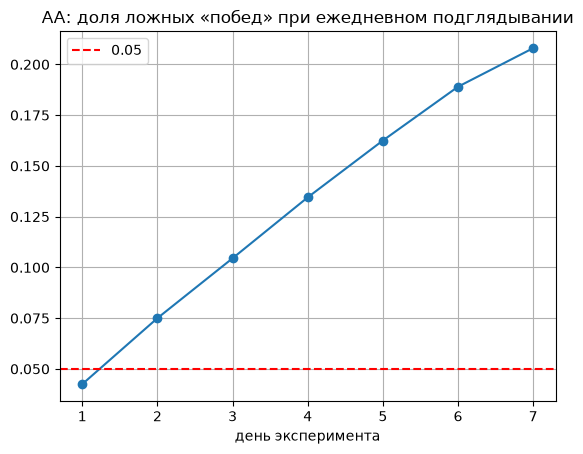

In [17]:
plt.plot(range(1, len(week_days) + 1), np.maximum.accumulate(significant, axis=1).mean(axis=0), marker='o')
plt.axhline(ALPHA, color='r', linestyle='--', label='0.05')
plt.title('АА: доля ложных «побед» при ежедневном подглядывании')
plt.xlabel('день эксперимента')
plt.legend()
plt.grid()
plt.savefig('figures/peeking.png', dpi=120, bbox_inches='tight')
plt.show()

За неделю ежедневных проверок ошибка I рода вырастает в несколько раз.</br>
Длительность теста надо фиксировать заранее (по MDE), а не останавливать при первой значимости.

А так менялся p-value в настоящем exp3:

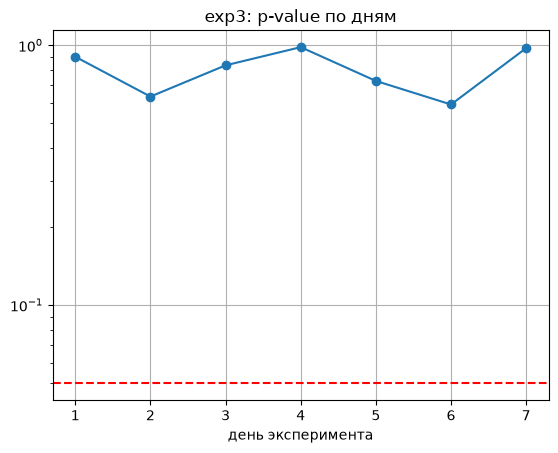

In [18]:
users_a, users_b = exp_dict['exp3']['users_a'], exp_dict['exp3']['users_b']
cum = daily.cumsum(axis=1)
pvalues_by_day = [stats.ttest_ind(cum.loc[users_a, d], cum.loc[users_b, d]).pvalue for d in week_days]
plt.plot(range(1, 8), pvalues_by_day, marker='o')
plt.axhline(ALPHA, color='r', linestyle='--')
plt.title('exp3: p-value по дням')
plt.xlabel('день эксперимента')
plt.yscale('log')
plt.grid()
plt.show()

# Выводы

1. Разбиение на группы во всех экспериментах корректное: до эксперимента группы не отличаются (pvalue 0.56-0.78).
2. **exp1** (+3.3%, pvalue 0.11) - незначимо, но MDE был 5.8%. Тест слишком маленький, чтобы говорить, что эффекта нет. Если гипотеза важная - перезапустить на большей выборке.
3. **exp2** (+2.9%, pvalue < 0.001, ДИ [48; 113]) - эффект есть, можно катить.
4. **exp3** - эффекта нет, и ДИ узкий (±0.8% от среднего): если эффект и есть, то совсем небольшой.
5. Выручка за прошлую неделю - плохая ковариата для CUPED на этих данных (корреляция -0.17). Средний чек за историю работает лучше (0.31), дисперсия падает на 7-10%. exp1 и с CUPED остаётся незначимым (pvalue 0.07).
6. Ежедневное подглядывание с остановкой при первой значимости поднимает ошибку I рода с ~4% до ~21%.

Что можно попробовать дальше: ковариату из ML-модели по нескольким признакам истории (CUPAC), бутстреп для доверительных интервалов, поправки на множественное тестирование, если смотреть сразу несколько метрик.